# Document processing: report-level sentiment

Runs the single extraction script over the 10-K and 10-Q samples in `input_data/`
and writes report-level polarities to `sentiment_extraction_results/`.

All the logic lives in `code/scripts/`; this notebook runs it.

Runtime setup detects Colab and clones this public repository there when needed. Locally, it finds the checkout from the current directory and its parents.

One procedure for both form types: the filing is split into token-budgeted chunks,
each chunk gets the prompt ending appended, one token position is read out, the
top-p words is matched against the verbalizer, and the chunk scores are averaged
into one row per filing.

Each filing is keyed by `(CIK, FILING_DATE, ACC_NUM, FORM_TYPE)`, so a re-run
resumes exactly where it stopped and merges stay safe.

In [1]:
# !pip install torch
!pip install langchain_text_splitters --quiet
# !pip install transformers

In [2]:
import subprocess
import sys
from pathlib import Path
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)

REPO_URL = "https://github.com/fabianslo108/manager_sentiment.git"
try:
    import google.colab
except ModuleNotFoundError:
    IS_COLAB = False
else:
    IS_COLAB = True

def is_repository(path):
    return (path / "code" / "scripts" / "utils.py").is_file() and (path / "input_data").is_dir()

search_paths = (Path.cwd().resolve(), *Path.cwd().resolve().parents)
REPO_ROOT = next((path for path in search_paths if is_repository(path)), None)

if REPO_ROOT is None and IS_COLAB:
    REPO_ROOT = Path("/content/manager_sentiment")
    if not REPO_ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO_ROOT)], check=True)
    elif not is_repository(REPO_ROOT):
        raise FileExistsError(f"{REPO_ROOT} exists but is not a valid manager_sentiment checkout")

if REPO_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the repository. Run this notebook from within the manager_sentiment checkout."
    )

sys.path.insert(0, str(REPO_ROOT / "code" / "scripts"))

from utils import INPUT_DATA_DIR, SENTIMENT_RESULTS_DIR, clean_mem, set_seed
from reports import discover_reports
from prompts import STRATEGIES
from sentiment_extraction import ExtractionConfig, ScoringBackend, run_extraction

set_seed(42)

if not INPUT_DATA_DIR.is_dir():
    raise FileNotFoundError(f"Expected input folder was not found: {INPUT_DATA_DIR}")
input_file_count = sum(1 for _ in INPUT_DATA_DIR.glob("*.txt"))
if input_file_count == 0:
    raise FileNotFoundError(f"No filing .txt files were found in {INPUT_DATA_DIR}")


print("runtime:", "Colab" if IS_COLAB else "local")
print("repo:", REPO_ROOT)
print("input:", INPUT_DATA_DIR)
print("input files:", input_file_count)
print("output:", SENTIMENT_RESULTS_DIR)
print("strategies:", sorted(STRATEGIES))

runtime: Colab
repo: /content/manager_sentiment
input: /content/manager_sentiment/input_data
input files: 100
output: /content/manager_sentiment/sentiment_extraction_results
strategies: ['financial_risk', 'growth', 'growth_legacy_causal']


## Sample

File names carry the filing key:
`{FILING_DATE}_{FORM_TYPE}_edgar_data_{CIK}_{ACC_NUM}.txt`.

In [3]:
sample = discover_reports(INPUT_DATA_DIR)

print(sample["FORM_TYPE"].value_counts().to_string())
print()
print("filing years:", sorted(sample["FILING_DATE"].str[:4].unique()))
sample.head()

12:39:44 | INFO    | reports | discovered 100 filing(s) under /content/manager_sentiment/input_data


FORM_TYPE
10-Q    50
10-K    50

filing years: ['2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']


,CIK,FILING_DATE,ACC_NUM,FORM_TYPE,SECTION,path
0,101295,20211112,0001171843-21-007870,10-Q,None,/content/manager_sentiment/input_data/20211112...
1,1022408,20220526,0001140361-22-020620,10-K,None,/content/manager_sentiment/input_data/20220526...
2,1046995,20140313,0001013762-14-000233,10-K,None,/content/manager_sentiment/input_data/20140313...
3,1069533,20171208,0001069533-17-000036,10-K,None,/content/manager_sentiment/input_data/20171208...
4,1070412,20150206,0001070412-15-000009,10-K,None,/content/manager_sentiment/input_data/20150206...


## Configuration

`chunk_size_tokens=None` keeps the earlier convention: chunk size is the model
window minus a reserve for the prompt ending (1000 tokens for a causal LM, 100
for a masked LM). Note what that implies per model:

- **ModernBERT-large** (window 8192) chunks long filings.
- **Llama-3.1-8B** (window 131072) leaves ~130k tokens per chunk, so almost
  every filing is a single chunk and the averaging step is a no-op.

Set `chunk_size_tokens` explicitly (e.g. 4096) if the two models should see the
same amount of text per readout.

The repository does not contain model weights. Download Llama 3.1 8B and
ModernBERT-large with the commented commands in `code/scripts/download_models.sh`,
then set `MODEL_ID` to the local directory or to the Hugging Face id.

In [4]:
MODEL_ID = "meta-llama/Meta-Llama-3.1-8B" # or local directory with models weights
# MODEL_ID = "answerdotai/ModernBERT-large"
STRATEGY = "growth"                        # "growth" | "financial_risk"

common = dict(
    model_id=MODEL_ID,
    strategy=STRATEGY,
    input_dir=INPUT_DATA_DIR,
    output_dir=SENTIMENT_RESULTS_DIR,
    chunk_overlap_tokens=240,
    top_p=0.9,
    docs_per_batch=2,
    save_every=200,
    resume=True,
)

cfg_10q = ExtractionConfig(form_type="10-Q", **common)
cfg_10k = ExtractionConfig(form_type="10-K", **common)

for cfg in (cfg_10q, cfg_10k):
    print(cfg.form_type, "->", cfg.resolve_output_path().name)

10-Q -> growth__Meta-Llama-3_1-8B__10Q.csv
10-K -> growth__Meta-Llama-3_1-8B__10K.csv


## Smoke test

Score a handful of filings first. Watch the log lines for the resolved chunk
size and for any verbalizer words that have no single-token form -- those
contribute nothing to the score.

In [5]:
from dataclasses import replace

smoke = replace(cfg_10q, limit=5, output_name=f"_smoke_{STRATEGY}_10Q.csv", resume=False)
smoke_result = run_extraction(smoke)
smoke_result

12:40:31 | INFO    | reports | discovered 50 filing(s) under /content/manager_sentiment/input_data
12:40:31 | INFO    | sentiment_extraction | scoring 5 filing(s) with strategy 'growth'


config.json:   0%|          | 0.00/826 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/50.5k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/73.0 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/185 [00:00<?, ?B/s]

12:41:39 | INFO    | sentiment_extraction | loaded meta-llama/Meta-Llama-3.1-8B as causal backend on cuda (window=131072, vocab=128256)
12:41:39 | INFO    | sentiment_extraction | prompt ending: Future growth prospects appear to be
12:41:40 | INFO    | sentiment_extraction | verbalizer: 81 positive / 58 negative vocabulary ids; 1 positive word(s) unreachable as a single token; 4 negative word(s) unreachable as a single token
12:41:40 | WARNING | sentiment_extraction | positive words with no single-token form: reassured
12:41:40 | WARNING | sentiment_extraction | negative words with no single-token form: apprehensive, dissatisfied, pessimistic, unsatisfied
12:41:40 | INFO    | sentiment_extraction | chunking at 130072 token(s) (window 131072 - reserve 1000), overlap 240
12:41:55 | WARNING | sentiment_extraction | CUDA OOM: retrying with 4 chunk(s) per forward pass
12:41:56 | WARNING | sentiment_extraction | CUDA OOM: retrying with 2 chunk(s) per forward pass
12:41:58 | WARNING | sentime

,CIK,FILING_DATE,ACC_NUM,FORM_TYPE,SECTION,strategy,model,backend,positive,negative,polarity,n_chars,n_chars_scored,decode_fallback
0,101295,20211112,0001171843-21-007870,10-Q,None,growth,meta-llama/Meta-Llama-3.1-8B,causal,0.308868,0.231642,0.077225,61571,61571,False
1,108385,20211105,0000108385-21-000135,10-Q,None,growth,meta-llama/Meta-Llama-3.1-8B,causal,0.418391,0.117482,0.300909,103811,103811,False
2,16732,20211208,0000016732-21-000160,10-Q,None,growth,meta-llama/Meta-Llama-3.1-8B,causal,0.353502,0.125273,0.228229,78440,78440,False
3,20520,20210805,0001562762-21-000309,10-Q,None,growth,meta-llama/Meta-Llama-3.1-8B,causal,0.218791,0.202892,0.015898,520704,520704,False
4,215466,20210428,0000215466-21-000071,10-Q,None,growth,meta-llama/Meta-Llama-3.1-8B,causal,0.436869,0.086063,0.350806,105589,105589,False


#### Inspect a random report

In [15]:
from reports import ReportDataset
from prompts import normalize_token

backend = ScoringBackend(cfg_10q)
strategy = STRATEGIES[STRATEGY]

items = list(i for i in ReportDataset(sample[sample["FORM_TYPE"] == "10-Q"]) if i.ok)
item = np.random.choice(items)
prompt = strategy.build_prompt(item.text[:20_000], backend.kind, backend.mask_token)

print(item.key)
print("ending:", strategy.ending(backend.kind, backend.mask_token))
print()
for token, prob in backend.top_tokens(prompt, k=20):
    word = normalize_token(token)
    side = (
        "positive" if word in strategy.verbalizer["positive"]
        else "negative" if word in strategy.verbalizer["negative"]
        else ""
    )
    print(f"  {prob:7.4f}  {token!r:20s} {side}")

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

13:03:54 | INFO    | sentiment_extraction | loaded meta-llama/Meta-Llama-3.1-8B as causal backend on cuda (window=131072, vocab=128256)


('4447', '20210506', '0001628280-21-009296', '10-Q')
ending: Future growth prospects appear to be

   0.1616  ' limited'           negative
   0.0524  ' favorable'         positive
   0.0463  ' good'              positive
   0.0408  ' promising'         positive
   0.0281  ' uncertain'         negative
   0.0248  ' adversely'         
   0.0233  ' more'              
   0.0205  ' very'              
   0.0181  ' threatened'        
   0.0160  ' affected'          
   0.0150  ' most'              
   0.0150  ' at'                
   0.0141  ' excellent'         positive
   0.0133  ' increasingly'      
   0.0133  ' strong'            positive
   0.0133  ' positive'          positive
   0.0133  ' improving'         
   0.0125  ' the'               
   0.0125  ' in'                
   0.0125  ' significantly'     


In [ ]:
del backend
clean_mem()

## Full run

Safe to interrupt and re-run: finished filings are skipped on resume.

In [16]:
res_10q = run_extraction(cfg_10q)
res_10q.shape

13:04:33 | INFO    | reports | discovered 50 filing(s) under /content/manager_sentiment/input_data
13:04:33 | INFO    | sentiment_extraction | scoring 50 filing(s) with strategy 'growth'


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

13:04:40 | INFO    | sentiment_extraction | loaded meta-llama/Meta-Llama-3.1-8B as causal backend on cuda (window=131072, vocab=128256)
13:04:40 | INFO    | sentiment_extraction | prompt ending: Future growth prospects appear to be
13:04:41 | INFO    | sentiment_extraction | verbalizer: 81 positive / 58 negative vocabulary ids; 1 positive word(s) unreachable as a single token; 4 negative word(s) unreachable as a single token
13:04:41 | WARNING | sentiment_extraction | positive words with no single-token form: reassured
13:04:41 | WARNING | sentiment_extraction | negative words with no single-token form: apprehensive, dissatisfied, pessimistic, unsatisfied
13:04:41 | INFO    | sentiment_extraction | chunking at 130072 token(s) (window 131072 - reserve 1000), overlap 240
13:04:53 | WARNING | sentiment_extraction | CUDA OOM: retrying with 4 chunk(s) per forward pass
13:04:54 | WARNING | sentiment_extraction | CUDA OOM: retrying with 2 chunk(s) per forward pass
13:04:55 | WARNING | sentime

(50, 14)

In [17]:
res_10k = run_extraction(cfg_10k)
res_10k.shape

13:20:39 | INFO    | reports | discovered 50 filing(s) under /content/manager_sentiment/input_data
13:20:39 | INFO    | sentiment_extraction | scoring 50 filing(s) with strategy 'growth'


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

13:20:46 | INFO    | sentiment_extraction | loaded meta-llama/Meta-Llama-3.1-8B as causal backend on cuda (window=131072, vocab=128256)
13:20:46 | INFO    | sentiment_extraction | prompt ending: Future growth prospects appear to be
13:20:47 | INFO    | sentiment_extraction | verbalizer: 81 positive / 58 negative vocabulary ids; 1 positive word(s) unreachable as a single token; 4 negative word(s) unreachable as a single token
13:20:47 | WARNING | sentiment_extraction | positive words with no single-token form: reassured
13:20:47 | WARNING | sentiment_extraction | negative words with no single-token form: apprehensive, dissatisfied, pessimistic, unsatisfied
13:20:47 | INFO    | sentiment_extraction | chunking at 130072 token(s) (window 131072 - reserve 1000), overlap 240
13:25:35 | INFO    | sentiment_extraction | done: 50 filing(s) scored, 0 failure(s) in 4.8 min -> /content/manager_sentiment/sentiment_extraction_results/growth__Meta-Llama-3_1-8B__10K.csv


(50, 14)

## Results overview

One row per filing: `positive`, `negative` and `polarity = positive - negative`.

In [18]:
scores = pd.concat([res_10q, res_10k], ignore_index=True)

cols = ["positive", "negative", "polarity"]
scores.groupby("FORM_TYPE")[cols].describe().T.round(4)

FORM_TYPE          10-K     10-Q
positive count  50.0000  50.0000
         mean    0.4141   0.3973
         std     0.1262   0.0750
         min     0.0834   0.2188
         25%     0.3541   0.3608
         50%     0.4311   0.4194
         75%     0.5009   0.4491
         max     0.6082   0.5056
negative count  50.0000  50.0000
         mean    0.1384   0.1084
         std     0.1002   0.0486
         min     0.0177   0.0353
         25%     0.0641   0.0758
         50%     0.1217   0.0962
         75%     0.2078   0.1375
         max     0.5334   0.2461
polarity count  50.0000  50.0000
         mean    0.2757   0.2889
         std     0.2171   0.1200
         min    -0.4499  -0.0115
         25%     0.1465   0.2121
         50%     0.3200   0.3244
         75%     0.4352   0.3758
         max     0.5611   0.4703

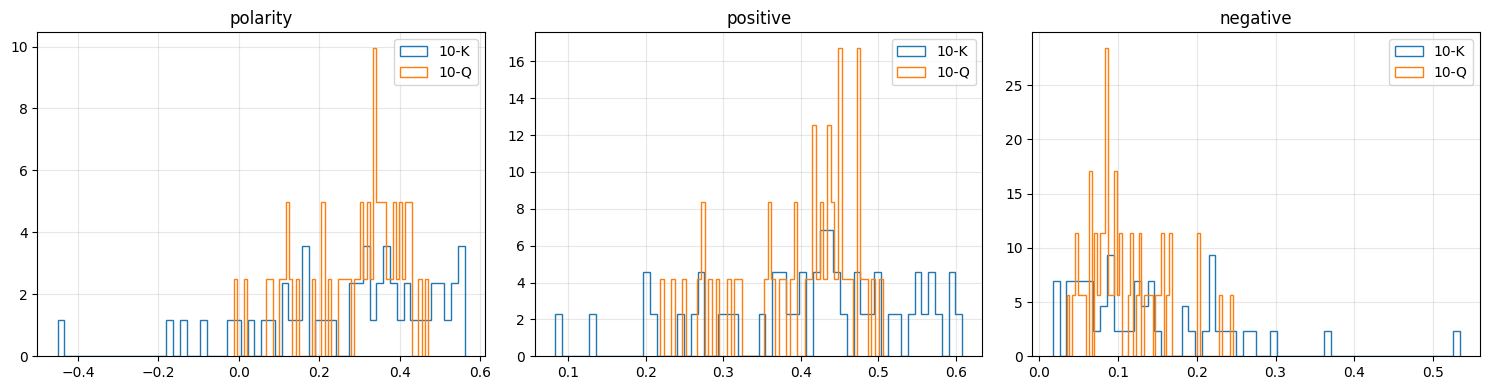

In [19]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for form, group in scores.groupby("FORM_TYPE"):
    axes[0].hist(group["polarity"], bins=60, histtype="step", density=True, label=form)
    axes[1].hist(group["positive"], bins=60, histtype="step", density=True, label=form)
    axes[2].hist(group["negative"], bins=60, histtype="step", density=True, label=form)

for ax, title in zip(axes, ["polarity", "positive", "negative"]):
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [20]:
# Anything that could not be scored, with the reason.
for cfg in (cfg_10q, cfg_10k):
    path = cfg.resolve_output_path()
    failures = path.with_name(path.stem + ".failures.csv")
    if failures.exists():
        frame = pd.read_csv(failures)
        print(f"{cfg.form_type}: {len(frame)} failure(s)")
        print(frame["reason"].str.split(":").str[0].value_counts().to_string())
    else:
        print(f"{cfg.form_type}: no failures")

10-Q: no failures
10-K: no failures
